# ML Engineer notebook: Customers Like You

**Tanay Mihani (ML Engineer).** The data side (cleaning, split, matrix) is Achintya's, in `Data_Engineer.ipynb`.

This notebook takes the training matrix Achintya built and does ML1 to ML7. Run `Data_Engineer.ipynb` first so `data/processed/` exists, then run this one top to bottom from the repo root. Figures go to `figures/` and the key numbers to `results/results.json`.

1. Setup
2. ML1: method decision (written before fitting anything)
3. Load the matrix and check it
4. Size of the compressed version at each k
5. Dated training lines (for validation and ML7)
6. ML2: SVD for each k, reconstruction error
7. Validation split
8. Scoring products for a customer
9. Choosing the scoring method and k
10. ML3: the final model and the product page box
11. ML4: test hit rate vs best sellers, and timing the nightly job
12. ML5: PCA vs SVD
13. ML6: customer map
14. ML7: does the purchase value matter?
15. Saving the results
16. Summary

## 1. Setup

In [1]:
import os, io, json, time, tempfile, tracemalloc
from contextlib import redirect_stdout

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

SEED = 42                      # used for every random step (R6)
PROC = "data/processed"        # written by Data_Engineer.ipynb
K_GRID = [10, 20, 50, 100, 200]
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

## 2. ML1: Method decision

I'm writing this before fitting anything, so the choice isn't influenced by the results.

**Main method: Truncated SVD.** PCA gets run later on the same matrix with the same k, as the comparison for ML5.

Why SVD:

1. **The matrix is almost all zeros.** It's 5,456 customers × 3,680 products, 1/0 "ever bought", and 97.95% of the cells are 0. Stored sparse it's about 5 MB, dense it would be 160.6 MB. `TruncatedSVD` works on the sparse matrix directly and never has to fill in the zeros.
2. **PCA centres first, and that breaks the sparsity.** Subtracting each product's average turns every 0 into a small negative number, so the centred matrix has about 20 million non-zero cells instead of 411,136. scikit-learn 1.4+ avoids actually building it: with the `arpack` solver it multiplies the sparse matrix as usual and subtracts a small correction for the averages. So the speed gap might be smaller than it sounds, and I'll measure it in ML5 instead of assuming it. It still means PCA is decomposing a different matrix from the one we built.
3. **SVD's components fit the job, and this is the main reason.** For "customers who bought this also bought", I want products that get bought by the same customers. SVD on the raw matrix captures that co-buying directly. PCA's components describe how customers differ from the average customer, which is a less direct fit for recommending products.
4. **One fit gives both sides.** SVD gives customer factors (U·S) and product factors (V) at the same time: product factors for the similar-products box, customer factors for the customer map.

Where PCA might do better: it reports explained variance, which is an easier number to give Sarah than reconstruction error, and for the customer map, centring puts the average customer in the middle of the plot. I'll check this in ML5 with my own numbers instead of assuming it.

**Prediction to check later:** SVD's first component will mostly measure how much a customer buys overall (big buyers get big values), not a particular kind of product.

### How I'll choose k (also decided before fitting)

Candidates: k = 10, 20, 50, 100, 200. I'll use two kinds of evidence:

1. **Reconstruction error vs k**, ‖A − A_k‖ / ‖A‖ (Frobenius norm). Look for the elbow, where adding more components stops reducing the error much.
2. **Hit rate at 10 vs k.** Pick the smallest k within 1 percentage point of the best hit rate, because a smaller k is cheaper to store and faster to run.

The test months can't be used to choose k, because then the final test score would be optimistic (R2). So k gets chosen on a **validation split inside the training period**: learn from everything before 9 Aug 2011, check against new products bought from 9 Aug to 9 Oct 2011. That's the same two-month setup as the real test. Then I refit on the full training matrix with the chosen k and score the test set once. This needs the matrix rebuilt with an earlier cutoff, which I've asked Achintya to support in `build_matrix.py`.

### How hit rate gets counted

- **Test customers:** all 1,919 customers in `heldout.csv`. These are customers in the training matrix who bought at least one product they had never bought before in the test months.
- **Hit:** at least one of the customer's held-out products is in their top 10. Products they already bought in training are never recommended.
- **Products outside the matrix:** about 9.5% of held-out purchases are products that aren't in the matrix (new products, or ones bought by fewer than 10 customers). Neither the model nor the baseline can ever recommend them. I keep them in, and they count as misses for both, so the comparison stays fair. I report how many customers this affects (cell below).
- **Baseline (R3):** the 10 products with the most distinct buyers in training (`n_customers` in `products.csv`), skipping any the customer already bought. I use distinct buyers rather than units so one wholesaler's huge order can't make something a "best seller".

## 3. Load the matrix and check it

Customer IDs never get loaded here (R4). From `customers_internal.csv` I only read the row index and the country.

In [2]:
A = sp.load_npz(f"{PROC}/A_train.npz").tocsr()
products = pd.read_csv(f"{PROC}/products.csv", dtype={"StockCode": str})
customers = pd.read_csv(f"{PROC}/customers_internal.csv", usecols=["row", "Country"])
heldout = pd.read_csv(f"{PROC}/heldout.csv", dtype={"StockCode": str})
heldout["prod_col"] = heldout["prod_col"].astype("Int64")
with open(f"{PROC}/matrix_report.json") as f:
    report = json.load(f)

n_cust, n_prod = A.shape
dense_mb = n_cust * n_prod * 8 / 1e6
sparse_mb = (A.data.nbytes + A.indices.nbytes + A.indptr.nbytes) / 1e6
print(f"Matrix: {n_cust:,} customers x {n_prod:,} products, {A.nnz:,} non-zeros, "
      f"{1 - A.nnz / (n_cust * n_prod):.2%} zeros")
print(f"Values stored: {np.unique(A.data)}  (should only be 1)")
print(f"Memory: dense {dense_mb:.1f} MB vs sparse {sparse_mb:.2f} MB")

# Same numbers as Achintya's matrix report, and the index files line up with the matrix
assert (n_cust, n_prod, A.nnz) == (report["customers"], report["products"], report["non_zeros"])
assert len(products) == n_prod and len(customers) == n_cust
assert (products["col"].to_numpy() == np.arange(n_prod)).all()
assert (customers["row"].to_numpy() == np.arange(n_cust)).all()
# 1/0 matrix, so column sums are the number of distinct buyers per product
assert (np.asarray(A.sum(axis=0)).ravel() == products["n_customers"].to_numpy()).all()
print("Matches matrix_report.json")

Matrix: 5,456 customers x 3,680 products, 411,136 non-zeros, 97.95% zeros
Values stored: [1.]  (should only be 1)
Memory: dense 160.6 MB vs sparse 4.96 MB
Matches matrix_report.json


In [3]:
test_rows = heldout["cust_row"].unique()
in_mat = heldout[heldout["in_matrix"]]
reachable = in_mat["cust_row"].unique()
per_cust = heldout.groupby("cust_row").size()

print(f"Test customers: {len(test_rows):,}")
print(f"Held-out purchases: {len(heldout):,}, of which {(~heldout['in_matrix']).mean():.1%} are products outside the matrix")
print(f"Customers with at least one held-out product that can be recommended: "
      f"{len(reachable):,} ({len(reachable) / len(test_rows):.1%})")
print(f"Held-out products per test customer: median {per_cust.median():.0f}, max {per_cust.max():,}")

# Leak check: no held-out purchase should already be a 1 in the training matrix
already = A[in_mat["cust_row"].to_numpy(), in_mat["prod_col"].to_numpy(dtype=int)]
assert np.asarray(already).sum() == 0
print("Leak check passed: no held-out purchase appears in the training matrix")

Test customers: 1,919
Held-out purchases: 49,214, of which 9.5% are products outside the matrix
Customers with at least one held-out product that can be recommended: 1,903 (99.2%)
Held-out products per test customer: median 17, max 462
Leak check passed: no held-out purchase appears in the training matrix


## 4. How big would the compressed version be?

After compressing to k components I keep two small tables: customer factors (customers × k) and product factors (products × k), each number taking 8 bytes. This is just arithmetic, no fitting.

In [4]:
print(f"Dense matrix {dense_mb:.1f} MB, sparse matrix {sparse_mb:.2f} MB\n")
for k in K_GRID:
    mb = (n_cust + n_prod) * k * 8 / 1e6
    print(f"k = {k:>3}: factors {mb:5.2f} MB  |  {dense_mb / mb:4.0f}x smaller than dense  |  "
          f"{mb / sparse_mb:.1f}x the sparse matrix")

Dense matrix 160.6 MB, sparse matrix 4.96 MB

k =  10: factors  0.73 MB  |   220x smaller than dense  |  0.1x the sparse matrix
k =  20: factors  1.46 MB  |   110x smaller than dense  |  0.3x the sparse matrix
k =  50: factors  3.65 MB  |    44x smaller than dense  |  0.7x the sparse matrix
k = 100: factors  7.31 MB  |    22x smaller than dense  |  1.5x the sparse matrix
k = 200: factors 14.62 MB  |    11x smaller than dense  |  2.9x the sparse matrix


Every k on the list is at least 10x smaller than the dense matrix, so the size target in the README holds whatever k I pick. The sparse file is already small, though, and from k = 100 up the factors are bigger than it. So the real saving is against the full customer × product score table the old prototype built (dense size), not against the sparse file. That goes in the memo.

## 5. Dated training lines

The matrix only says who bought what. I also need dates for the validation split and quantities for ML7. Neither `Data_Engineer.ipynb` nor `build_matrix.py` saves the cleaned lines, and `build_matrix.py` always writes into `data/processed/`, so I run the code cells of Achintya's notebook in a separate namespace and take his cleaned training lines (`train_df`) from there. His output files get sent to a temporary folder, so nothing in `data/processed/` is overwritten, and I check that his code rebuilds exactly the matrix I loaded.

Customer IDs are in `train_df`, but they stay in memory and only get used to map lines to matrix rows (R4).

In [5]:
def run_data_engineer(path="Data_Engineer.ipynb"):
    # run every code cell of Achintya's notebook, but point its OUT folder at a temp dir
    nb = json.load(open(path))
    ns = {}
    with tempfile.TemporaryDirectory() as tmp, redirect_stdout(io.StringIO()):
        for cell in nb["cells"]:
            if cell["cell_type"] == "code":
                exec("".join(cell["source"]), ns)
                if "OUT" in ns:
                    ns["OUT"] = tmp
    return ns

t = time.perf_counter()
de = run_data_engineer()
train_lines = de["train_df"]
cust_idx, prod_idx, cutoff = de["cust_idx"], de["prod_idx"], de["cutoff_date"]
assert (de["A"] != A).nnz == 0, "Data_Engineer.ipynb no longer rebuilds A_train.npz"
del de
print(f"Ran Data_Engineer.ipynb in {time.perf_counter() - t:.0f} s, rebuilt matrix matches A_train.npz")

# only lines for customers and products that are in the matrix
lines = train_lines[train_lines["Customer ID"].isin(cust_idx.index)
                    & train_lines["StockCode"].isin(prod_idx.index)].copy()
lines["row"] = lines["Customer ID"].map(cust_idx).to_numpy()
lines["col"] = lines["StockCode"].map(prod_idx).to_numpy()
print(f"Training lines in the matrix: {len(lines):,}, "
      f"{lines['InvoiceDate'].min():%d %b %Y} to {lines['InvoiceDate'].max():%d %b %Y} (test cutoff {cutoff:%d %b %Y})")

Ran Data_Engineer.ipynb in 3 s, rebuilt matrix matches A_train.npz
Training lines in the matrix: 653,020, 01 Dec 2009 to 09 Oct 2011 (test cutoff 09 Oct 2011)


## 6. ML2: SVD for each k

Relative reconstruction error is ‖A − A_k‖ / ‖A‖ (Frobenius). A_k = A V Vᵀ is A projected onto the top k product directions, so by Pythagoras ‖A − A_k‖² = ‖A‖² − ‖A V‖² and I never have to build the dense 160 MB A_k. I check that shortcut against the dense calculation once, at k = 10.

In [6]:
fro2 = A.multiply(A).sum()
rows = []
for k in K_GRID:
    t = time.perf_counter()
    svd_k = TruncatedSVD(n_components=k, random_state=SEED).fit(A)
    secs = time.perf_counter() - t
    Z = svd_k.transform(A)                       # customer factors, U*S
    rows.append({"k": k, "fit seconds": round(secs, 2),
                 "rel. reconstruction error": round(float(np.sqrt(1 - (Z ** 2).sum() / fro2)), 3),
                 "variance explained": round(float(svd_k.explained_variance_ratio_.sum()), 3)})
    if k == 10:
        A_10 = svd_k.inverse_transform(Z)
        dense_err = np.linalg.norm(A.toarray() - A_10) / np.sqrt(fro2)
        del A_10
ml2 = pd.DataFrame(rows).set_index("k")
assert abs(dense_err - ml2.loc[10, "rel. reconstruction error"]) < 1e-3
print(f"Shortcut check at k = 10: dense {dense_err:.4f}, shortcut {ml2.loc[10, 'rel. reconstruction error']:.3f}")
ml2

Shortcut check at k = 10: dense 0.8980, shortcut 0.898


,fit seconds,rel. reconstruction error,variance explained
k,,,
10,0.06,0.898,0.154
20,0.06,0.876,0.195
50,0.12,0.832,0.273
100,0.20,0.781,0.360
200,0.41,0.702,0.482


The error is high at every k (it only drops from about 0.9 to 0.7). That's expected for a 1/0 matrix that's 98% zeros: most individual purchases are one-offs that no small set of components can rebuild. What the components do keep is the shared buying patterns, which is what recommendations need. Whether that's enough has to be judged by hit rate, not by this number, so the choice of k comes from the validation split below.

## 7. Validation split

Same setup as the real test, moved two months earlier so it only uses training data. I learn from purchases before the validation cutoff, then check against products customers bought for the first time between the validation cutoff and the real test cutoff. I keep Achintya's customers and products (same rows and columns as A), so only products in the matrix count here. The test months are never touched.

In [7]:
val_cut = cutoff - pd.DateOffset(months=2)
before = (lines["InvoiceDate"] < val_cut).to_numpy()

fit_pairs = lines.loc[before, ["row", "col"]].drop_duplicates()
A_fit = sp.csr_matrix((np.ones(len(fit_pairs)), (fit_pairs["row"], fit_pairs["col"])), shape=A.shape)

after = lines.loc[~before, ["row", "col"]].drop_duplicates()
seen = np.asarray(A_fit[after["row"].to_numpy(), after["col"].to_numpy()]).ravel()
new = after[seen == 0]
has_history = np.diff(A_fit.indptr) > 0
new = new[has_history[new["row"].to_numpy()]]

val_truth = new.groupby("row")["col"].apply(set).to_dict()
val_rows = np.array(sorted(val_truth))
val_allowed = np.asarray(A_fit.sum(axis=0)).ravel() > 0   # no buyers before val_cut means nothing to score it with

print(f"Validation cutoff: {val_cut:%d %b %Y %H:%M}")
print(f"Fit matrix: {A_fit.nnz:,} non-zeros (full training matrix: {A.nnz:,})")
print(f"Validation customers: {len(val_rows):,}, first-time purchases to find: {len(new):,}")
print(f"Products with no buyers before the validation cutoff: {(~val_allowed).sum()}")

Validation cutoff: 09 Aug 2011 12:50
Fit matrix: 371,764 non-zeros (full training matrix: 411,136)
Validation customers: 1,420, first-time purchases to find: 29,194
Products with no buyers before the validation cutoff: 105


## 8. Scoring products for a customer

All three options below score a product by adding up how similar it is to everything the customer already bought. They only differ in what "similar" means:

- **cosine V** (the starter code): product vectors are rows of V, scaled to length 1.
- **cosine VS**: each component weighted by its singular value first, then scaled to length 1.
- **dot V**: plain dot products of the rows of V, no scaling. Adding these up over a customer's purchases is exactly their row of the rank-k rebuild A V Vᵀ.

Products the customer already bought are never recommended. The baseline (R3) ranks products by distinct buyers.

In [8]:
METHODS = ["cosine V", "cosine VS", "dot V"]

def product_vectors(model, method):
    V = model.components_.T
    if method == "cosine V":
        return normalize(V)
    if method == "cosine VS":
        return normalize(V * model.singular_values_)
    return V

def svd_scorer(model, method):
    P = product_vectors(model, method)
    return lambda part: (part @ P) @ P.T

def popularity_scorer(A_hist):
    pop = np.asarray(A_hist.sum(axis=0)).ravel()
    return lambda part: np.tile(pop, (part.shape[0], 1))

def top_n(scorer, A_hist, rows, n=10, allowed=None, batch=1000):
    # top n products for each customer in rows, best first, skipping what they already bought
    out = np.empty((len(rows), n), dtype=int)
    for s in range(0, len(rows), batch):
        part = A_hist[rows[s:s + batch]]
        scores = np.asarray(scorer(part), dtype=float)
        scores[part.nonzero()] = -np.inf
        if allowed is not None:
            scores[:, ~allowed] = -np.inf
        top = np.argpartition(-scores, n, axis=1)[:, :n]
        order = np.argsort(-np.take_along_axis(scores, top, axis=1), axis=1)
        out[s:s + batch] = np.take_along_axis(top, order, axis=1)
    return out

def hit_rate(recs, rows, truth):
    return float(np.mean([len(truth.get(r, set()) & set(rec)) > 0 for r, rec in zip(rows, recs)]))

## 9. Choosing the scoring method and k

Every method and k is fitted on `A_fit` and scored on the validation customers. Rule (from ML1): take the method with the best validation hit rate, then the smallest k within 1 percentage point of that method's best.

In [9]:
val_results = []
for k in K_GRID:
    model_k = TruncatedSVD(n_components=k, random_state=SEED).fit(A_fit)
    for m in METHODS:
        recs = top_n(svd_scorer(model_k, m), A_fit, val_rows, allowed=val_allowed)
        val_results.append({"k": k, "method": m, "hit rate": hit_rate(recs, val_rows, val_truth)})
val_table = pd.DataFrame(val_results).pivot(index="k", columns="method", values="hit rate")[METHODS]
val_base = hit_rate(top_n(popularity_scorer(A_fit), A_fit, val_rows, allowed=val_allowed), val_rows, val_truth)

METHOD = val_table.max().idxmax()
best = val_table[METHOD].max()
K = int(min(k for k in K_GRID if val_table.loc[k, METHOD] >= best - 0.01))

print(f"Validation hit rate at 10 (%), best-seller baseline = {val_base:.1%}")
print((val_table * 100).round(1))
print(f"\nBest method: {METHOD} (best {best:.1%} at k = {val_table[METHOD].idxmax()})")
print(f"Chosen k = {K}, smallest k within 1 point of the best")

Validation hit rate at 10 (%), best-seller baseline = 24.9%
method  cosine V  cosine VS  dot V
k                                 
10          12.7        9.3   33.7
20          17.0       13.2   36.5
50          21.5       18.3   40.2
100         24.0       23.1   41.9
200         23.0       33.2   39.2

Best method: dot V (best 41.9% at k = 100)
Chosen k = 100, smallest k within 1 point of the best


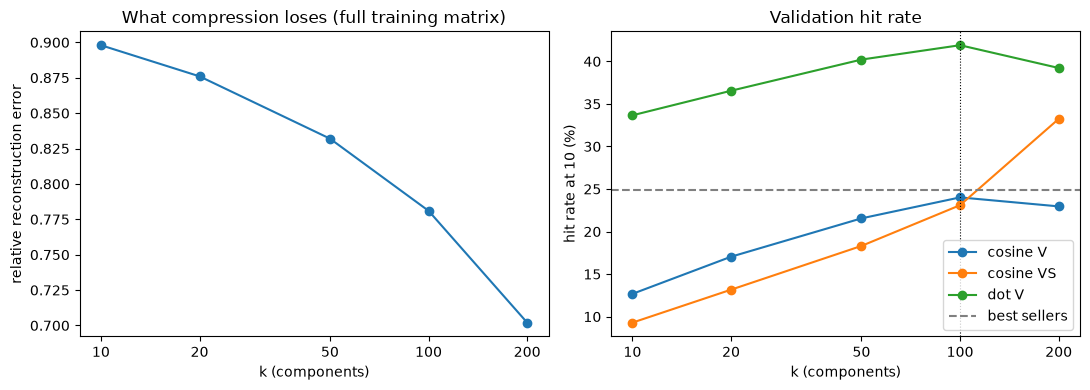

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ml2.index, ml2["rel. reconstruction error"], marker="o")
ax[0].set(xlabel="k (components)", ylabel="relative reconstruction error", title="What compression loses (full training matrix)")
for m in METHODS:
    ax[1].plot(val_table.index, val_table[m] * 100, marker="o", label=m)
ax[1].axhline(val_base * 100, color="grey", ls="--", label="best sellers")
ax[1].axvline(K, color="black", lw=0.8, ls=":")
ax[1].set(xlabel="k (components)", ylabel="hit rate at 10 (%)", title="Validation hit rate")
ax[1].legend()
for a in ax:
    a.set_xscale("log")
    a.set_xticks(K_GRID)
    a.set_xticklabels(K_GRID)
    a.minorticks_off()
fig.tight_layout()
fig.savefig("figures/choosing_k.png", dpi=150)
plt.show()

**What validation says.** dot V is the best method at every k, by a wide margin. At k = 100 it finds a first-time purchase for 41.9% of the 1,420 validation customers, against 24.9% for best sellers. The cosine versions do much worse: the starter code's cosine V never beats best sellers (its best is 24.0%), and cosine VS only gets past them at k = 200 (33.2%). Scaling every product vector to length 1 throws away how strongly a product is tied to the main buying patterns, and that's mostly popularity, so the cosine scores end up suggesting niche look-alikes. The dot product keeps it.

dot V peaks at k = 100. k = 50 is 1.7 points lower, so the 1-point rule picks k = 100. At k = 200 it drops again, which I read as the extra components starting to fit one-off purchases. The reconstruction error curve has no clear elbow (it just keeps going down), so the hit rate is what decided k.

## 10. ML3: the final model and the product page box

Refit on the full training matrix with the chosen k. There are two outputs:

- **Product page box:** top 10 most similar products for every product, by cosine on V·S. On a product page there's only that one product to go on. Since AᵀA ≈ V S² Vᵀ, the cosine between two rows of V·S approximates the cosine between those two products' columns in A, which measures how much their buyers overlap.
- **Customer suggestions:** top 10 per customer with the method picked on validation.

In [11]:
t = time.perf_counter()
svd = TruncatedSVD(n_components=K, random_state=SEED).fit(A)
svd_fit_secs = time.perf_counter() - t
P_box = normalize(svd.components_.T * svd.singular_values_)
desc = products["Description"].str.strip().to_numpy()

def similar(j, n=10):
    s = P_box @ P_box[j]
    s[j] = -np.inf
    return np.argsort(-s)[:n]

def recommend(rows, n=10):
    return top_n(svd_scorer(svd, METHOD), A, np.asarray(rows), n=n)

for j in products["n_customers"].nlargest(3).index:
    print(f"{desc[j]}\n    also bought: " + "; ".join(desc[similar(j, 5)]))

WHITE HANGING HEART T-LIGHT HOLDER
    also bought: RED HANGING HEART T-LIGHT HOLDER; CANDLEHOLDER PINK HANGING HEART; HANGING METAL HEART LANTERN; CREAM HEART CARD HOLDER; WHITE METAL LANTERN
REGENCY CAKESTAND 3 TIER
    also bought: ROSES REGENCY TEACUP AND SAUCER; GREEN REGENCY TEACUP AND SAUCER; PINK REGENCY TEACUP AND SAUCER; SET OF 3 REGENCY CAKE TINS; RED RETROSPOT CAKE STAND
PACK OF 72 RETROSPOT CAKE CASES
    also bought: PACK OF 60 PINK PAISLEY CAKE CASES; 60 TEATIME FAIRY CAKE CASES; PACK OF 60 DINOSAUR CAKE CASES; 72 SWEETHEART FAIRY CAKE CASES; PACK OF 72 SKULL CAKE CASES


## 11. ML4: test hit rate and the nightly job

Now the held-out test purchases get used, once, with the k and method already fixed. All 1,919 test customers count, including the 16 whose new products are all outside the matrix (misses for both).

In [12]:
test_rows = np.sort(heldout["cust_row"].unique())
test_truth = in_mat.groupby("cust_row")["prod_col"].apply(lambda s: set(s.astype(int))).to_dict()

model_recs = recommend(test_rows)
base_recs = top_n(popularity_scorer(A), A, test_rows)
model_hr = hit_rate(model_recs, test_rows, test_truth)
base_hr = hit_rate(base_recs, test_rows, test_truth)

def correct_in_top10(recs):
    return float(np.mean([len(test_truth.get(r, set()) & set(rec)) for r, rec in zip(test_rows, recs)]))

print(f"Test customers: {len(test_rows):,}")
print(f"Hit rate at 10, SVD (k = {K}, {METHOD}): {model_hr:.1%}")
print(f"Hit rate at 10, best sellers:           {base_hr:.1%}")
print(f"Difference: {100 * (model_hr - base_hr):+.1f} points ({model_hr / base_hr:.2f}x)")
print(f"Correct products per top 10, on average: SVD {correct_in_top10(model_recs):.2f}, best sellers {correct_in_top10(base_recs):.2f}")

Test customers: 1,919


Hit rate at 10, SVD (k = 100, dot V): 40.9%
Hit rate at 10, best sellers:           26.5%
Difference: +14.4 points (1.54x)
Correct products per top 10, on average: SVD 0.66, best sellers 0.36


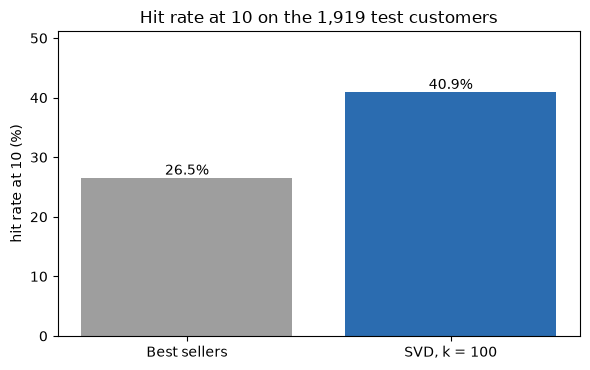

In [13]:
fig, ax = plt.subplots(figsize=(6, 3.8))
bars = ax.bar(["Best sellers", f"SVD, k = {K}"], [base_hr * 100, model_hr * 100], color=["#9e9e9e", "#2b6cb0"])
ax.bar_label(bars, fmt="%.1f%%")
ax.set(ylabel="hit rate at 10 (%)", title="Hit rate at 10 on the 1,919 test customers")
ax.set_ylim(0, max(base_hr, model_hr) * 125)
fig.tight_layout()
fig.savefig("figures/hit_rate.png", dpi=150)
plt.show()

Timing the whole nightly job: fit, the product page table for all 3,680 products, and top 10 for all 5,456 customers.

In [14]:
def nightly_job(A, k):
    secs = {}
    t = time.perf_counter()
    model = TruncatedSVD(n_components=k, random_state=SEED).fit(A)
    secs["fit"] = time.perf_counter() - t

    t = time.perf_counter()
    P = normalize(model.components_.T * model.singular_values_)
    box = np.empty((P.shape[0], 10), dtype=int)
    for s in range(0, P.shape[0], 1000):
        sims = P[s:s + 1000] @ P.T
        sims[np.arange(len(sims)), np.arange(s, s + len(sims))] = -np.inf
        box[s:s + 1000] = np.argsort(-sims, axis=1)[:, :10]
    secs["product pages"] = time.perf_counter() - t

    t = time.perf_counter()
    recs = top_n(svd_scorer(model, METHOD), A, np.arange(A.shape[0]))
    secs["all customers"] = time.perf_counter() - t
    secs["total"] = sum(secs.values())
    return box, recs, secs

box, all_recs, job_secs = nightly_job(A, K)
for part, s in job_secs.items():
    print(f"{part:>14}: {s:.2f} s")

           fit: 0.21 s
 product pages: 0.62 s
 all customers: 0.21 s
         total: 1.04 s


Post-check, **not** used for any choice: the test hit rate at every k, to see whether the validation split pointed at a sensible k.

In [15]:
post = {k: hit_rate(top_n(svd_scorer(TruncatedSVD(n_components=k, random_state=SEED).fit(A), METHOD), A, test_rows),
                    test_rows, test_truth) for k in K_GRID}
print({k: f"{v:.1%}" for k, v in post.items()})

{10: '34.9%', 20: '37.8%', 50: '40.9%', 100: '40.9%', 200: '39.8%'}


**Test result.** With k = 100 and dot V fixed, 40.9% of the 1,919 test customers had at least one of their next new purchases in their top 10, against 26.5% for best sellers. That's 14.4 points more, about 1.5 times as often, and on average 0.66 of the 10 suggestions were right against 0.36. The validation hit rate (41.9%) was close to the test one, so the validation split was a fair stand-in for the test.

The post-check shows k = 50 and k = 100 tie on the test set (both 40.9%). So k = 50 would have done just as well at half the size, but validation couldn't see that, and I'm not changing k after looking at the test set. The whole nightly job takes about a second (the exact time moves a little between runs), far under the 60-second target.

## 12. ML5: PCA vs SVD

PCA on the same matrix with the same k (`arpack`, which centres implicitly on sparse input). Peak memory is measured with `tracemalloc` in a separate fit, so tracing doesn't slow down the timed one. For PCA's hit rate I use the same scoring as SVD, with PCA's components in place of V; for the dot-product version that means the PCA rebuild, mean + (a − mean) W Wᵀ.

In [16]:
def peak_mb(fit):
    tracemalloc.start()
    fit()
    peak = tracemalloc.get_traced_memory()[1]
    tracemalloc.stop()
    return peak / 1e6

t = time.perf_counter()
pca = PCA(n_components=K, svd_solver="arpack", random_state=SEED).fit(A)
pca_fit_secs = time.perf_counter() - t
svd_peak = peak_mb(lambda: TruncatedSVD(n_components=K, random_state=SEED).fit(A))
pca_peak = peak_mb(lambda: PCA(n_components=K, svd_solver="arpack", random_state=SEED).fit(A))

def pca_scorer(model, method):
    W, mu = model.components_.T, model.mean_
    if method == "dot V":
        offset = mu - (mu @ W) @ W.T
        return lambda part: (part @ W) @ W.T + offset
    P = normalize(W) if method == "cosine V" else normalize(W * model.singular_values_)
    return lambda part: (part @ P) @ P.T

pca_hr = hit_rate(top_n(pca_scorer(pca, METHOD), A, test_rows), test_rows, test_truth)

Z_svd, Z_pca = svd.transform(A), pca.transform(A)
centred2 = fro2 - n_cust * (pca.mean_ ** 2).sum()                  # ||A - mean||^2
svd_err = float(np.sqrt(1 - (Z_svd ** 2).sum() / fro2))
pca_err = float(np.sqrt((centred2 - (Z_pca ** 2).sum()) / fro2))    # error of mean + Z W^T, relative to ||A||

basket = np.asarray(A.sum(axis=1)).ravel()
c1 = {}
for name, Zc, comp in [("SVD", Z_svd, svd.components_[0]), ("PCA", Z_pca, pca.components_[0])]:
    c1[name] = {"corr_basket": abs(np.corrcoef(Zc[:, 0], basket)[0, 1]),
                "corr_popularity": abs(np.corrcoef(comp, products["n_customers"])[0, 1]),
                "top": "; ".join(desc[np.argsort(-np.abs(comp))[:3]])}

def comp1_words(name):
    return (f"how much a customer buys overall (corr {c1[name]['corr_basket']:.2f} with products bought); "
            f"loadings follow product popularity (corr {c1[name]['corr_popularity']:.2f})")

ml5 = pd.DataFrame({
    "PCA": [K, round(pca_fit_secs, 2), round(pca_peak, 1), round((n_cust * K + n_prod * K + n_prod) * 8 / 1e6, 2),
            f"{pca.explained_variance_ratio_.sum():.1%} variance explained, rel. error {pca_err:.3f}",
            f"{pca_hr:.1%}", f"{base_hr:.1%}", comp1_words("PCA")],
    "Truncated SVD": [K, round(svd_fit_secs, 2), round(svd_peak, 1), round((n_cust + n_prod) * K * 8 / 1e6, 2),
                      f"rel. error {svd_err:.3f} ({svd.explained_variance_ratio_.sum():.1%} variance explained)",
                      f"{model_hr:.1%}", f"{base_hr:.1%}", comp1_words("SVD")],
}, index=["k used", "Fit time (seconds)", "Peak memory during fit (MB)", "Size of stored factors (MB)",
          "Variance explained or relative reconstruction error", "Hit rate at 10 on held-out purchases",
          "Best-seller baseline hit rate at 10", "What component 1 represents"])
with pd.option_context("display.max_colwidth", None):
    print(ml5.to_string())
print("\nTop products on component 1:", {n: c1[n]["top"] for n in c1})

                                                                                                                                                                   PCA                                                                                                      Truncated SVD
k used                                                                                                                                                             100                                                                                                                100
Fit time (seconds)                                                                                                                                                 0.3                                                                                                               0.21
Peak memory during fit (MB)                                                                                                                               

**PCA vs SVD, in my numbers.** The gap turned out to be small on this matrix. PCA gets 40.2% against 40.9%, takes a bit longer to fit (both well under half a second; see the table for this run), and stores almost the same amount (it also keeps the 3,680 product averages). PCA's peak memory was even a little lower (16.6 vs 17.8 MB), which shows the implicit centring never builds the dense matrix (that alone would be 160 MB). Both keep about 36% of the variance.

The reason they're so close: the product averages are tiny. The median product was bought by 1.2% of customers and 90% of products by under 5%, so subtracting the averages barely moves the matrix.

My ML1 prediction held for SVD: component 1 is basket size (corr 0.98 with products bought) and its loadings follow popularity (corr 0.99). PCA's component 1 turned out to be basket size too (0.98), because the biggest buyers are also the customers furthest from the average one. So the "PCA describes differences from the average customer" argument in ML1 mattered less in practice than I expected. I'm keeping SVD as the main method: same results, a bit faster, and it works on the matrix exactly as Achintya built it.

## 13. ML6: customer map

For the map I use a separate 10-component SVD instead of the recommender's k: groups for marketing only need the broad patterns, and this way the segments don't change if k changes. Component 1 is basically basket size (section 12), so I drop it and scale each customer's remaining 9 numbers to length 1. That groups customers by *what* they buy, not *how much*. k-means is run for 3 to 6 groups, and I keep the number with the best silhouette score. Groups are numbered from biggest to smallest.

"Signature products" are the products most over-represented in a group compared with all customers, among products bought by at least 15% of that group.

In [17]:
map_svd = TruncatedSVD(n_components=10, random_state=SEED).fit(A)
X = normalize(map_svd.transform(A)[:, 1:])

sil = {}
for g in range(3, 7):
    lab = KMeans(n_clusters=g, n_init=10, random_state=SEED).fit_predict(X)
    sil[g] = silhouette_score(X, lab, sample_size=3000, random_state=SEED)
G = max(sil, key=sil.get)
print("Silhouette:", {g: round(s, 3) for g, s in sil.items()}, "-> groups:", G)

lab = KMeans(n_clusters=G, n_init=10, random_state=SEED).fit_predict(X)
by_size = pd.Series(lab).value_counts().index
groups = pd.Series(lab).map({old: new for new, old in enumerate(by_size)}).to_numpy()

overall = np.asarray(A.mean(axis=0)).ravel()
country = customers["Country"].to_numpy()
profile, signature = [], {}
for g in range(G):
    m = groups == g
    share = np.asarray(A[m].mean(axis=0)).ravel()
    lift = np.where(share >= 0.15, share / overall, 0)
    top = np.argsort(-lift)[:5]
    others = pd.Series(country[m])
    others = others[others != "United Kingdom"].value_counts().head(3)
    profile.append({"group": g, "customers": int(m.sum()),
                    "median products bought": int(np.median(basket[m])),
                    "UK": f"{(country[m] == 'United Kingdom').mean():.0%}",
                    "top non-UK countries": ", ".join(others.index),
                    "signature products": "; ".join(f"{desc[j].title()} ({share[j]:.0%} vs {overall[j]:.0%})" for j in top)})
    signature[g] = " | ".join(desc[np.argsort(-lift)[:8]]).upper()
profile = pd.DataFrame(profile).set_index("group")
with pd.option_context("display.max_colwidth", None):
    print(profile.to_string())

Silhouette: {3: 0.135, 4: 0.141, 5: 0.15, 6: 0.155} -> groups: 6
       customers  median products bought   UK          top non-UK countries                                                                                                                                                                                                    signature products
group                                                                                                                                                                                                                                                                                            
0           1321                      36  98%   Netherlands, Spain, Germany                 Heart Ivory Trellis Large (17% vs 8%); Zinc Metal Heart Decoration (24% vs 11%); Heart Of Wicker Large (29% vs 14%); Single Heart Zinc T-Light Holder (17% vs 8%); Heart Of Wicker Small (30% vs 14%)
1            945                      47  89%  France, Germany, N

I named the groups from their signature products. To keep each name attached to the right group even if k-means numbers them differently on another machine, each name comes with a few words from its products, and a group gets the name whose words show up most in its top 8 signature products. Anything that doesn't match stays "Group n".

                              name  customers  median products bought   UK
group                                                                     
0      Heart and wicker home decor       1321                      36  98%
1      Traditional toys and crafts        945                      47  89%
2                Funny metal signs        935                      32  96%
3           Regency tea and baking        830                      42  90%
4            Kids' party tableware        718                      46  80%
5           Jumbo bags and storage        707                      55  89%


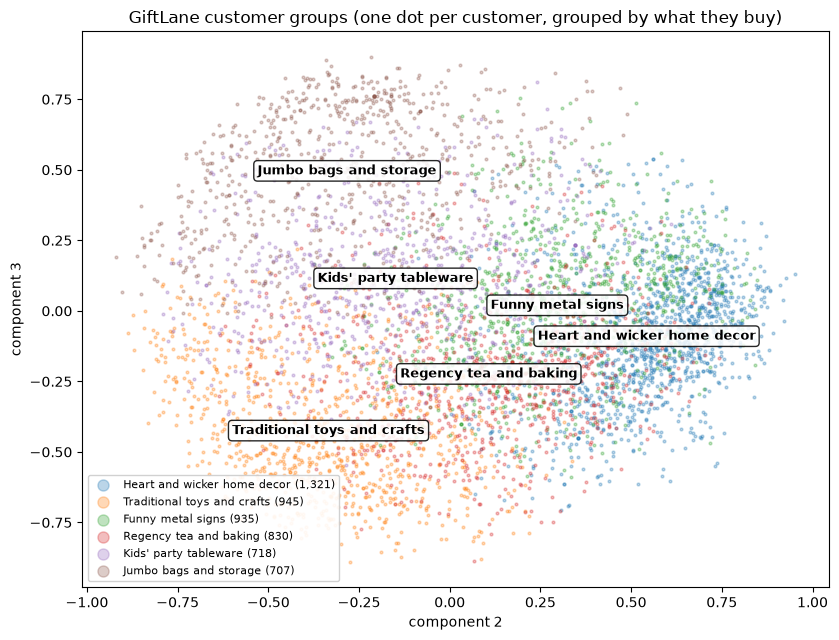

In [18]:
SEGMENT_WORDS = {
    "Heart and wicker home decor": ["HEART", "WICKER", "T-LIGHT"],
    "Traditional toys and crafts": ["PAINT SET", "CLAY", "DOMINOES", "CRAYONS", "HARMONICA"],
    "Funny metal signs": [" SIGN"],
    "Regency tea and baking": ["REGENCY", "TEACUP", "CAKE TINS"],
    "Kids' party tableware": ["PAPER", "CAKE CASES", "NAPKINS"],
    "Jumbo bags and storage": ["JUMBO", "STORAGE"],
}

def name_for(text):
    hits = {name: sum(text.count(w) for w in words) for name, words in SEGMENT_WORDS.items()}
    best = max(hits, key=hits.get)
    return best if hits[best] > 0 else None

names = {g: name_for(signature[g]) for g in range(G)}
taken = [n for n in names.values() if n]
names = {g: n if n and taken.count(n) == 1 else f"Group {g + 1}" for g, n in names.items()}
profile.insert(0, "name", [names[g] for g in profile.index])
print(profile[["name", "customers", "median products bought", "UK"]].to_string())
profile.to_csv("results/segments.csv")

fig, ax = plt.subplots(figsize=(8.5, 6.5))
for g in range(G):
    m = groups == g
    ax.scatter(X[m, 0], X[m, 1], s=4, alpha=0.3, label=f"{profile.loc[g, 'name']} ({m.sum():,})")
for g in range(G):
    m = groups == g
    ax.annotate(profile.loc[g, "name"], (X[m, 0].mean(), X[m, 1].mean()), ha="center", va="center",
                fontsize=9, weight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.85))
ax.set(xlabel="component 2", ylabel="component 3",
       title="GiftLane customer groups (one dot per customer, grouped by what they buy)")
ax.legend(markerscale=4, fontsize=8, loc="lower left", framealpha=0.9)
fig.tight_layout()
fig.savefig("figures/customer_map.png", dpi=150)
plt.show()

**The groups.** Six groups had the best silhouette, but every score is low (0.135 to 0.155). The groups overlap a lot, and you can see that on the map: they describe what a shop leans towards, not separate kinds of customer. Each group still has clear signature products, often 3 to 4 times as common as across all customers (31% of the jumbo bags group bought the Spaceboy jumbo bag, against 7% overall). Countries don't separate the groups much because 91% of customers are in the UK. The kids' party group is the most international (80% UK), and the jumbo bags group buys the widest range (median 55 products).

| Group | Customers | What they buy |
|---|---|---|
| Heart and wicker home decor | 1,321 | Hanging and wicker hearts, zinc T-light holders; 98% UK |
| Traditional toys and crafts | 945 | Vintage paint sets, modelling clay, dominoes, harmonicas |
| Funny metal signs | 935 | Novelty metal signs; the narrowest range (median 32 products) |
| Regency tea and baking | 830 | Regency teacups, teapots and cake tins |
| Kids' party tableware | 718 | Skull, dinosaur and spotty paper plates, cups, napkins, cake cases; 80% UK |
| Jumbo bags and storage | 707 | Jumbo bags in many prints; the widest range (median 55 products) |

## 14. ML7: does the purchase value matter?

Achintya's matrix uses 1/0. Here I rebuild it with the summed quantity per customer and product, and with log(1 + quantity), using the same rows, columns, k and scoring method. Each version is scored on the validation split (fit on the validation fit period) and on the test set (fit on all training). The main model stays on the 1/0 matrix, since the matrix was frozen on Day 4. This section is a finding and a possible next step, not a reason to switch at the end.

In [19]:
def value_matrix(part, value):
    q = part.groupby(["row", "col"])["Quantity"].sum()
    v = q.to_numpy(dtype=float)
    v = {"1/0": np.ones_like(v), "count": v, "log(1 + count)": np.log1p(v)}[value]
    r, c = q.index.get_level_values(0), q.index.get_level_values(1)
    return sp.csr_matrix((v, (r, c)), shape=A.shape)

assert (value_matrix(lines, "1/0") != A).nnz == 0
ml7 = []
for value in ["1/0", "count", "log(1 + count)"]:
    M_fit = value_matrix(lines[before], value)
    m_fit = TruncatedSVD(n_components=K, random_state=SEED).fit(M_fit)
    M_all = value_matrix(lines, value)
    m_all = TruncatedSVD(n_components=K, random_state=SEED).fit(M_all)
    ml7.append({"purchase value": value,
                "validation hit rate": hit_rate(top_n(svd_scorer(m_fit, METHOD), M_fit, val_rows, allowed=val_allowed), val_rows, val_truth),
                "test hit rate": hit_rate(top_n(svd_scorer(m_all, METHOD), M_all, test_rows), test_rows, test_truth)})
ml7 = pd.DataFrame(ml7).set_index("purchase value")
print(f"k = {K}, {METHOD}. Best sellers: validation {val_base:.1%}, test {base_hr:.1%}")
print((ml7 * 100).round(1))

k = 100, dot V. Best sellers: validation 24.9%, test 26.5%
                validation hit rate  test hit rate
purchase value                                    
1/0                            41.9           40.9
count                          23.3           22.4
log(1 + count)                 39.4           38.2


**Purchase value.** 1/0 is best on both validation (41.9%) and test (40.9%). Raw counts are much worse (22.4% on test, below best sellers): a few wholesalers ordering hundreds of units dominate the components, so the suggestions chase bulk items. log(1 + count) is close but still lower (38.2%). So Achintya's 1/0 choice was the right one for this job, and there's nothing here that argues for switching.

## 15. Saving the results

Everything the memo and slides quote, in one file. No customer IDs.

In [20]:
results = {
    "matrix": {"customers": n_cust, "products": n_prod, "non_zeros": int(A.nnz),
               "dense_mb": round(dense_mb, 1), "sparse_mb": round(sparse_mb, 2)},
    "chosen": {"k": K, "method": METHOD, "rule": "best method on validation, smallest k within 1 point of its best"},
    "ml2": ml2.reset_index().to_dict(orient="records"),
    "validation": {"cutoff": str(val_cut), "customers": int(len(val_rows)), "baseline": val_base,
                   "hit_rate": {str(k): val_table.loc[k].to_dict() for k in K_GRID}},
    "test": {"customers": int(len(test_rows)), "svd_hit_rate": model_hr, "baseline_hit_rate": base_hr,
             "post_check_by_k": {str(k): v for k, v in post.items()}},
    "nightly_job_seconds": {p: round(s, 2) for p, s in job_secs.items()},
    "factors_mb": round((n_cust + n_prod) * K * 8 / 1e6, 2),
    "svd": {"fit_seconds": round(svd_fit_secs, 2), "peak_mb": round(svd_peak, 1), "rel_error": round(svd_err, 3),
            "variance_explained": round(float(svd.explained_variance_ratio_.sum()), 3), "hit_rate": model_hr, "component_1": c1["SVD"]},
    "pca": {"fit_seconds": round(pca_fit_secs, 2), "peak_mb": round(pca_peak, 1), "rel_error": round(pca_err, 3),
            "variance_explained": round(float(pca.explained_variance_ratio_.sum()), 3), "hit_rate": pca_hr, "component_1": c1["PCA"]},
    "segments": profile.reset_index().to_dict(orient="records"),
    "silhouette": {str(g): round(float(s), 3) for g, s in sil.items()},
    "ml7": ml7.reset_index().to_dict(orient="records"),
}
with open("results/results.json", "w") as f:
    json.dump(results, f, indent=2, default=float)
print("Saved results/results.json")

Saved results/results.json


## 16. Summary

| README target | Result |
|---|---|
| Factors under 16 MB | 7.31 MB at k = 100, 22x smaller than the 160.6 MB dense matrix. Met |
| Nightly job under 60 s | About 1 s for the fit, the box for all 3,680 products and top 10 for all 5,456 customers. Met |
| Beat best sellers | Hit rate at 10 of 40.9% vs 26.5% on the 1,919 test customers. Met |
| Groups marketing can name | 6 groups, each named from its signature products. Met |

Things that go into the memo as risks:

- Products bought by fewer than 10 customers, and brand-new products, can never be suggested. They were 9.5% of the new purchases in the test months.
- New customers have no history, so they can only get best sellers.
- Everything was tested on one period, the two months before Christmas 2011.
- Suggestions lean towards popular products (component 1 is mostly popularity), so the box should be checked for variety.
- The groups overlap (low silhouette), so they're for steering campaigns, not hard labels.